# 01 - Chamada simples com LangGraph

Mesma pergunta do notebook `01-LLMs/02-Chamada simples - Langchain`, agora executada dentro de um grafo do **LangGraph**.

O grafo tem um único nó, que chama o modelo. Assim aparecem os conceitos básicos do LangGraph:

- **Estado:** `MessagesState`, uma lista de mensagens.
- **Nó:** função que recebe o estado e devolve atualizações.
- **Arestas:** ligações entre `START`, os nós e `END`.

As configurações de chave e modelo continuam vindo do `.env` na raiz do projeto.

In [1]:
import os

from dotenv import find_dotenv, load_dotenv
from IPython.display import Markdown, display
from IPython.display import Image
from langchain_openai import ChatOpenAI

load_dotenv(find_dotenv())

llm = ChatOpenAI(
    model=os.getenv("OPENAI_MODEL", "gpt-5-mini"),
    api_key=os.getenv("OPENAI_API_KEY"),
)

## 1. Definindo o grafo

O nó `modelo` recebe as mensagens do estado, chama o LLM e devolve a resposta. O `MessagesState` junta essa resposta ao histórico.

In [2]:
from langgraph.graph import END, START, MessagesState, StateGraph


def chamar_modelo(estado: MessagesState) -> dict:
    resposta = llm.invoke(estado["messages"])
    return {"messages": [resposta]}


grafo = StateGraph(MessagesState)
grafo.add_node("modelo", chamar_modelo)
grafo.add_edge(START, "modelo")
grafo.add_edge("modelo", END)

app = grafo.compile()

Visualizando a estrutura do grafo em Mermaid:

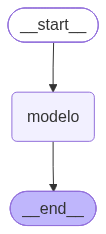

In [3]:
display(Image(app.get_graph().draw_mermaid_png()))


## 2. Executando o grafo

A entrada é um estado inicial com a pergunta. O resultado é o estado final, cuja última mensagem é a resposta do modelo.

In [4]:
pergunta = "Quem foi Isaac Newton?"

estado_final = app.invoke({"messages": [("user", pergunta)]})
resposta = estado_final["messages"][-1].content

display(Markdown(f"**Pergunta:** {pergunta}\n\n**Resposta:**\n\n{resposta}"))

**Pergunta:** Quem foi Isaac Newton?

**Resposta:**

Isaac Newton foi um matemático, físico, astrônomo e naturalista inglês — uma das figuras centrais da Revolução Científica. Nasceu em Woolsthorpe-by-Colsterworth, Lincolnshire, em 25 de dezembro de 1642 (calendário juliano) e morreu em 20 de março de 1727. Foi também alquimista e estudioso da Bíblia em investigações menos conhecidas.

Principais feitos
- Leis do movimento: formulou as três leis que descrevem o movimento dos corpos, base da mecânica clássica.
- Gravitação universal: propôs que todos os corpos se atraem com uma força proporcional às massas e inversamente proporcional ao quadrado da distância — explicando órbitas planetárias, marés, etc.
- Principia Mathematica (1687): obra-prima onde apresentou formalmente as leis do movimento e da gravitação; revolucionou a física.
- Cálculo: desenvolveu (independentemente de Leibniz) o cálculo diferencial e integral — chamado por ele de “fluxions”. Houve controvérsia sobre prioridade com Gottfried Leibniz.
- Óptica: estudou a luz e as cores, mostrou que a luz branca se decompõe em cores por meio de prismas e construiu o telescópio refletor (Newtonian telescope). Publicou Opticks (1704).
- Matemática: contribuiu com séries infinitas, o teorema binomial geral e métodos numéricos.

Carreira e reconhecimento
- Estudou e lecionou em Trinity College, Cambridge; foi Lucasian Professor de Matemática.
- Foi presidente da Royal Society e, mais tarde, mestre da Casa da Moeda (contribuiu no combate à falsificação).
- Recebeu o título de cavaleiro (Sir) em 1705.
- Foi sepultado na Abadia de Westminster.

Legado
Newton estabeleceu as bases da física clássica que dominaram a ciência até o século XX; sua metodologia e resultados influenciaram profundamente a ciência e a filosofia natural. Mesmo áreas menos convincentes (alquimia e cronologia bíblica) mostram a amplitude de seus interesses. Seu trabalho abriu caminho para desenvolvimentos posteriores em matemática, astronomia e tecnologia.